# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [9]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


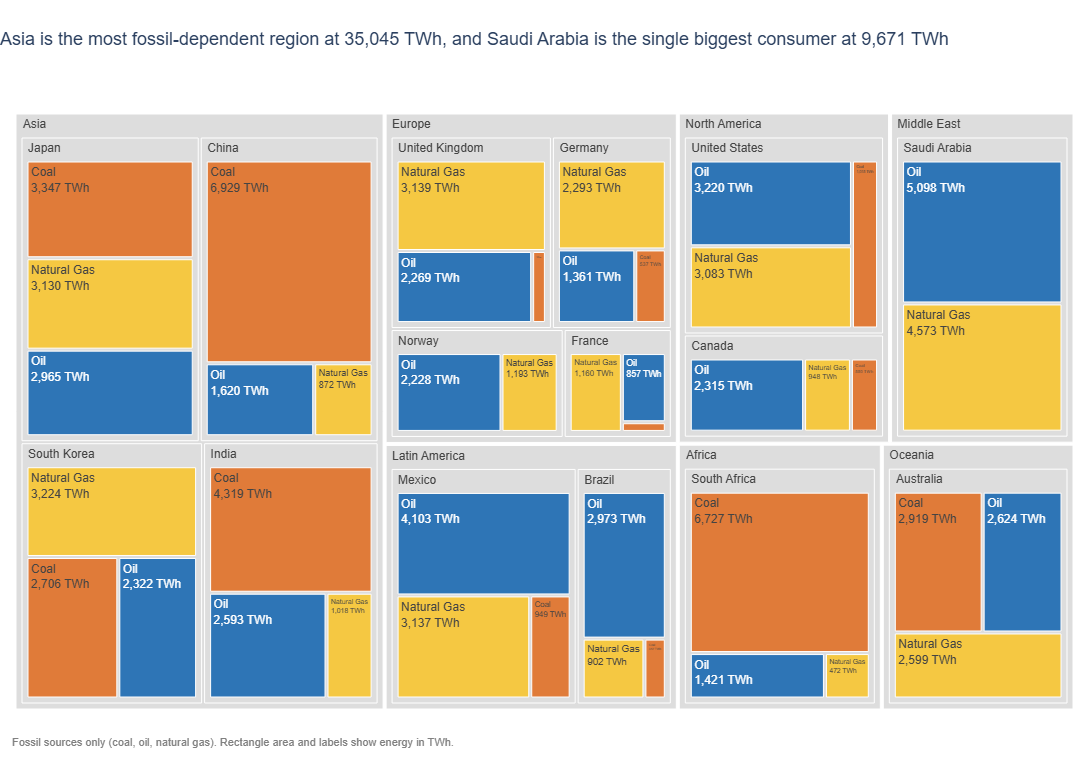

In [14]:
# Task 1
# 1. Filter to fossil sources only, BEFORE plotting
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# 2. CVD-safe colours (course palette): orange / blue / yellow differ in hue AND lightness,
#    and every leaf is also labelled directly, so hue never carries the meaning alone.
#    Coal is the accent colour of this exercise — Task 3 reuses it.
fossil_colors = {
    'Coal':        '#E07B39',   # orange
    'Oil':         '#2E75B6',   # blue
    'Natural Gas': '#F5C842',   # yellow
}
parent_grey = '#DDDDDD'         # Region and Country nodes are context, not data

# 3. Numbers for the insight title (absolute fossil TWh — the treemap encodes magnitude)
region_twh  = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
country_twh = df_fossil.groupby('Country')['TWh'].sum().sort_values(ascending=False)
top_region,  top_region_twh  = region_twh.index[0],  region_twh.iloc[0]
top_country, top_country_twh = country_twh.index[0], country_twh.iloc[0]

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',                                    # additive, so every parent sums correctly
    color='Source',
    color_discrete_map=fossil_colors,
    labels={'Source': 'Fossil source', 'TWh': 'Energy (TWh)'},
    height=750, width=1100,
    template='plotly_white')

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    # label + TWh only — no percentages
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
    marker_line_color='white', marker_line_width=1)

# Grey out parent nodes (Region and Country) — replace any colour that is not in the palette
fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else parent_grey
    for c in fig.data[0].marker.colors]

fig.update_layout(
    title=dict(
        text=(f'{top_region} is the most fossil-dependent region at {top_region_twh:,.0f} TWh, '
              f'and {top_country} is the single biggest consumer at {top_country_twh:,.0f} TWh'),
        x=0, xanchor='left', font=dict(size=18),    # left-aligned insight title
    ),
    font=dict(family='Arial', size=12),
    margin=dict(t=90, l=10, r=10, b=50),
)

# Footnote: what the reader is looking at
fig.add_annotation(
    text='Fossil sources only (coal, oil, natural gas). Rectangle area and labels show energy in TWh.',
    xref='paper', yref='paper', x=0, y=-0.03, xanchor='left', yanchor='top',
    showarrow=False, font=dict(size=11, color='grey'),
)

fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

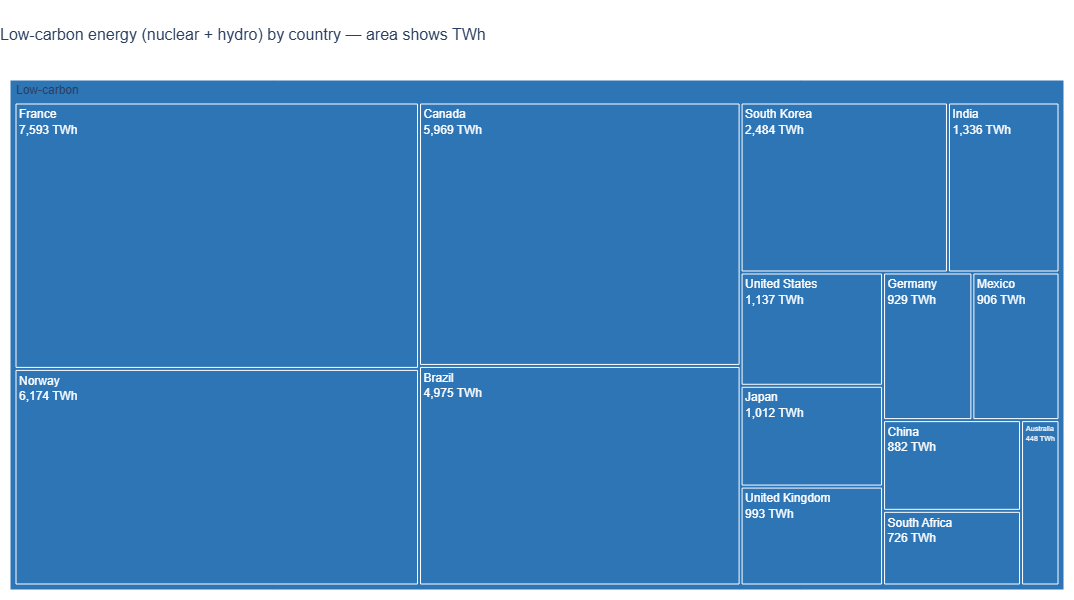

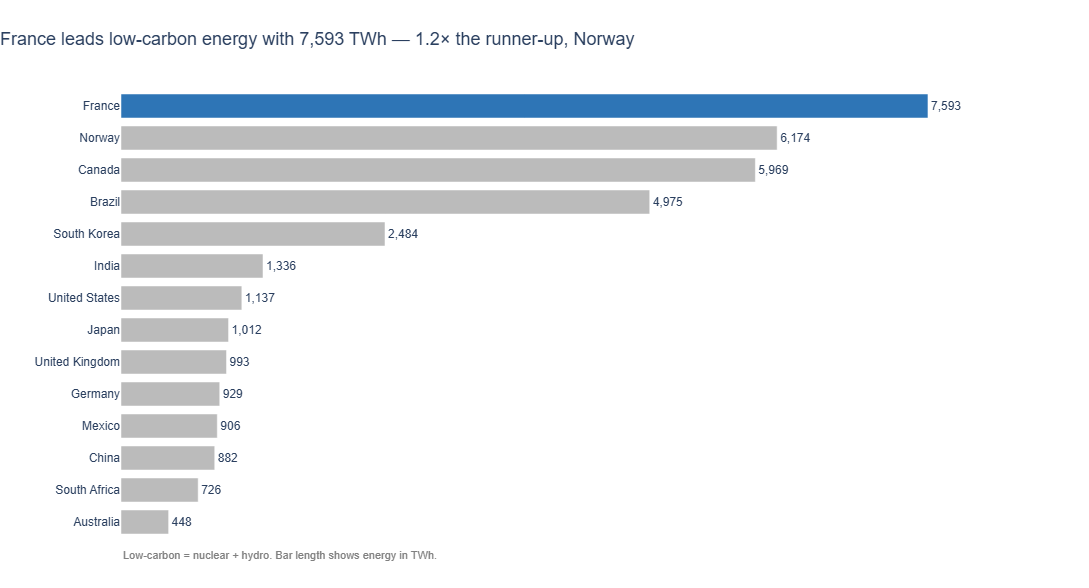

In [15]:
# Task 2 — charts
# ── Data prep ─────────────────────────────────────────────────────────────────
low = (df.loc[df['Source_Type'] == 'Low-carbon']
         .groupby('Country', as_index=False)['TWh'].sum()
         .sort_values('TWh', ascending=False))        # largest first

low['All']  = 'Low-carbon'      # dummy root node for the treemap
low['Type'] = 'Low-carbon'      # one category -> one colour

country_order = low['Country'].tolist()
leader,  leader_twh = country_order[0], low['TWh'].iloc[0]
second,  second_twh = country_order[1], low['TWh'].iloc[1]

low_blue = '#2E75B6'            # course palette blue = low-carbon (as in the lecture)
bar_grey = '#BBBBBB'

# ── Chart A: treemap (single level) ───────────────────────────────────────────
fig_tm = px.treemap(
    low,
    path=['All', 'Country'],
    values='TWh',
    color='Type',
    color_discrete_map={'Low-carbon': low_blue},
    labels={'TWh': 'Energy (TWh)'},
    height=600, width=1000,
    template='plotly_white',
)

fig_tm.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',          # TWh, no percentages
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
    marker_line_color='white', marker_line_width=1,
    root_color='white',
)

# Grey out the dummy root node
fig_tm.data[0].marker.colors = [
    c if c == low_blue else '#DDDDDD' for c in fig_tm.data[0].marker.colors
]

fig_tm.update_layout(
    title=dict(text='Low-carbon energy (nuclear + hydro) by country — area shows TWh',
               x=0, xanchor='left', font=dict(size=16)),
    font=dict(family='Arial', size=12),
    margin=dict(t=80, l=10, r=10, b=10),
)
fig_tm.show()

# ── Chart B: horizontal bar, sorted, one accent on the leader ─────────────────
low['Group'] = np.where(low['Country'] == leader, 'Leader', 'Others')
low['Label'] = low['TWh'].map('{:,.0f}'.format)             # direct labels instead of an axis

fig_bar = px.bar(
    low,
    x='TWh', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Leader': low_blue, 'Others': bar_grey},
    text='Label',
    category_orders={'Country': country_order},
    labels={'TWh': 'Low-carbon energy (TWh)'},
    hover_name='Country',
    hover_data={'Group': False, 'Label': False, 'TWh': ':,.0f'},
    height=max(420, 32 * len(low) + 140), width=1000,
    template='plotly_white',
)

fig_bar.update_traces(textposition='outside', cliponaxis=False,
                      textfont=dict(size=12))

fig_bar.update_layout(
    title=dict(
        text=(f'{leader} leads low-carbon energy with {leader_twh:,.0f} TWh — '
              f'{leader_twh / second_twh:.1f}× the runner-up, {second}'),
        x=0, xanchor='left', font=dict(size=18),
    ),
    font=dict(family='Arial', size=12),
    showlegend=False,
    bargap=0.25,
    xaxis=dict(visible=False, range=[0, low['TWh'].max() * 1.15]),   # room for the labels
    yaxis=dict(title='', categoryorder='array', categoryarray=country_order,
               autorange='reversed'),                                # largest at the top
    margin=dict(t=90, l=10, r=40, b=50),
)

fig_bar.add_annotation(
    text='Low-carbon = nuclear + hydro. Bar length shows energy in TWh.',
    xref='paper', yref='paper', x=0, y=-0.02, xanchor='left', yanchor='top',
    showarrow=False, font=dict(size=11, color='grey'),
)
fig_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE*

The horizontal bar chart tells the ranking story more clearly.

Length beats area. All bars share one baseline, so the reader compares length, which the eye judges much more accurately than area. In the treemap, two rectangles of similar size look almost identical and I have to read the numbers to know which is bigger.

Sorting shows the rank directly. The bars run from largest at the top to smallest at the bottom, so rank 1, 2, 3… can be read in order. A treemap packs its rectangles by size, but there is no clean top-to-bottom order to follow.

Design choices point at the answer. One accent colour on the leader, grey for the rest, value labels at the end of each bar and an insight title let the reader get the message at a glance.

The treemap's strength is not needed here. A treemap is the better choice for magnitude within a hierarchy or for many sub-categories (as in Task 1: Region → Country → Source). This chart has one level and one measure, so there is no nesting to show — the treemap only costs the reader precision.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

In [ ]:
# Task 3
# ── Data prep ─────────────────────────────────────────────────────────────────
# Reuse df_fossil from Task 1. pivot + stack gives every Region x Source pair (missing ones = 0 TWh)
agg = (df_fossil.pivot_table(index='Region', columns='Source', values='TWh',
                             aggfunc='sum', fill_value=0)
                .stack().rename('TWh').reset_index())

# Share of each region's fossil total -> bars sum to 100%
agg['Share'] = agg['TWh'] / agg.groupby('Region')['TWh'].transform('sum')

# Sort regions by coal share, highest first (top of the chart)
region_order = (agg.loc[agg['Source'] == 'Coal']
                   .sort_values('Share', ascending=False)['Region'].tolist())
source_order = ['Coal', 'Oil', 'Natural Gas']            # coal first -> on the baseline

# Percentage labels on the coal segments only; empty text everywhere else
agg['Label'] = np.where(agg['Source'] == 'Coal', agg['Share'].map('{:.0%}'.format), '')

# One accent colour (the SAME orange as Task 1) + two greys for context
accent_mapping = {
    'Coal':        fossil_colors['Coal'],   # orange accent — the story
    'Oil':         '#BBBBBB',               # mid grey
    'Natural Gas': '#DDDDDD',               # light grey
}

# Numbers for the insight title
top_coal_region = region_order[0]
top_coal_share = agg.loc[(agg['Region'] == top_coal_region) & (agg['Source'] == 'Coal'), 'Share'].iloc[0]

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.bar(
    data_frame=agg,
    x='Share', y='Region',
    orientation='h',
    color='Source',
    text='Label',
    color_discrete_map=accent_mapping,
    category_orders={'Region': region_order, 'Source': source_order},
    labels={'Share': "Share of region's fossil energy", 'Source': 'Fossil source'},
    hover_name='Region',
    hover_data={'Label': False, 'Share': ':.1%', 'TWh': ':,.0f'},
    height=max(380, 70 * len(region_order) + 160), width=1000,
    template='plotly_white',
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    textposition='inside', insidetextanchor='start',      # label at the left edge of the coal segment
    textfont=dict(color='#1A1A1A', size=12),
    marker_line_color='white', marker_line_width=1,       # thin white separators
)

fig.update_layout(
    title=dict(
        text=(f'{top_coal_region} relies most on coal: '
              f'{top_coal_share:.0%} of its fossil energy comes from coal'),
        x=0, xanchor='left', font=dict(size=18),
    ),
    font=dict(family='Arial', size=12),
    bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.08, title_text=''),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title='', categoryorder='array', categoryarray=region_order,
               autorange='reversed'),                    # highest coal share at the top
    margin=dict(t=110, l=10, r=40, b=60),
)

# Mark the end of the scale — every bar sums to 100%, and the hidden x-axis no longer says so
fig.add_annotation(
    x=1, y=0, xref='x', yref='paper', xanchor='right', yanchor='top', yshift=-4,
    text='100%', showarrow=False, font=dict(size=11, color='grey'),
)

# Footnote
fig.add_annotation(
    text="Each bar shows the split of one region's fossil energy (coal + oil + natural gas) by TWh.",
    xref='paper', yref='paper', x=0, y=-0.1, xanchor='left', yanchor='top',
    showarrow=False, font=dict(size=11, color='grey'),
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*

Only the treemap answers: "Which individual country burns the most fossil fuel in absolute terms, and how big is its coal / oil / gas block inside its region?" The treemap keeps the TWh values, so area shows magnitude, and it shows all three levels (Region → Country → Source) at once. The stacked bar cannot answer this: every bar is rescaled to 100%, so a huge region and a tiny region look the same length, and countries do not appear at all.


Only the stacked bar answers: "Which region depends most on coal compared with its own oil and gas, and how do regions rank on that share?" All bars share one baseline with coal on it, and the regions are sorted, so coal share can be compared precisely. The treemap cannot answer this: a region's total size dominates the area, so a coal-heavy but small region just looks small, and coal tiles in different regions cannot be compared as shares on a common baseline.